# Extended Data Fig. 4

Redraws all panels of Extended Data Fig. 4 from worksheets `ED_Fig4a`–`ED_Fig4f` of the figshare workbook
`Wilhelm_SourceData.xlsx`. All panels are heatmaps or scatter plots of the per-PTM / per-substitution values in the
workbook.

Data access: files are downloaded from the figshare article given by `FIGSHARE_ARTICLE_ID` (config cell below or environment variable; set `FIGSHARE_TOKEN` while the article is private) into `./data`, or read from a local copy of the deposit if the environment variable `SOURCE_DATA_DIR` points to it. Panels are saved to `regenerated_panels/ED_Fig4/` (PDF and PNG).

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path
import colorsys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import BoundaryNorm, to_rgb
from matplotlib.lines import Line2D

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig4'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(name):
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')


pd.set_option('display.max_colwidth', None)
readme('ED_Fig4')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 4,a,ED_Fig4a,NaN,"95th percentile of the absolute iRT prediction error per unseen PTM; rows = PTM encoding (atom count, gain loss; models trained with augmentation).",ED_Fig4a
1,Extended Data Fig. 4,b,ED_Fig4b,NaN,Median spectral angle (HCD spectra carrying the modification) per unseen PTM; rows = PTM encoding.,ED_Fig4b
2,Extended Data Fig. 4,c,ED_Fig4c,NaN,"One point per unseen amino-acid substitution; x = atom count, y = gain loss (95th percentile of the absolute iRT error).",ED_Fig4c
3,Extended Data Fig. 4,d,ED_Fig4d,NaN,"One point per unseen amino-acid substitution; x = atom count, y = gain loss (median spectral angle).",ED_Fig4d
4,Extended Data Fig. 4,e,ED_Fig4e,NaN,"One point per PTM; x = model trained without, y = model trained with sulfur-containing augmentations (median spectral angle).",ED_Fig4e
5,Extended Data Fig. 4,f,ED_Fig4f,NaN,"One point per PTM (seen / unseen PTM); x = gain loss without augmentation, y = augmentation only (median spectral angle).",ED_Fig4f


## a — iRT prediction error, unseen PTMs
95th percentile of the absolute iRT prediction error per unseen PTM; rows = PTM encoding (atom count, gain loss; models
trained with augmentation). Colour scale: `mako_r`, piecewise-linear boundaries from 2 to 50.

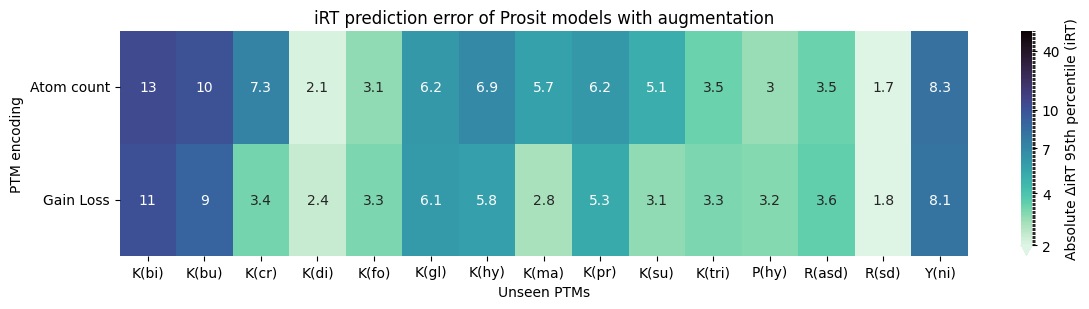

PTM,K(bi),K(bu),K(cr),K(di),K(fo),K(gl),K(hy),K(ma),K(pr),K(su),K(tri),P(hy),R(asd),R(sd),Y(ni)
PTM_encoding,,,,,,,,,,,,,,,
Atom count,13.0,10.0,7.3,2.1,3.1,6.2,6.9,5.7,6.2,5.1,3.5,3.0,3.5,1.7,8.3
Gain Loss,11.0,9.0,3.4,2.4,3.3,6.1,5.8,2.8,5.3,3.1,3.3,3.2,3.6,1.8,8.1


In [3]:
a = table('ED_Fig4a')
ptm_order = list(dict.fromkeys(a['PTM']))
mat = a.pivot(index='PTM_encoding', columns='PTM', values='absolute_delta_iRT_95th_percentile (iRT units)').loc[['Atom count', 'Gain Loss'], ptm_order]
bounds = np.concatenate([np.linspace(2, 4, 40), np.linspace(4, 7, 35)[1:], np.linspace(7, 10, 30)[1:], np.linspace(10, 50, 60)[1:]])
fig, ax = plt.subplots(figsize=(12, 3.2))
sns.heatmap(mat, cmap='mako_r', norm=BoundaryNorm(bounds, ncolors=256, extend='min'), annot=True, fmt='.2g',
            cbar_kws={'ticks': [2, 4, 7, 10, 40], 'format': '%g', 'label': 'Absolute ΔiRT 95th percentile (iRT)'}, ax=ax)
ax.set_xlabel('Unseen PTMs')
ax.set_ylabel('PTM encoding')
ax.set_title('iRT prediction error of Prosit models with augmentation')
plt.yticks(rotation=0)
plt.tight_layout()
save('ED_Fig4a')
plt.show()
mat

## b — spectral angle, unseen PTMs
Median spectral angle (HCD spectra carrying the modification) per unseen PTM; rows = PTM encoding. Colour scale: `mako`,
piecewise-linear boundaries from 0.5 to 0.93.

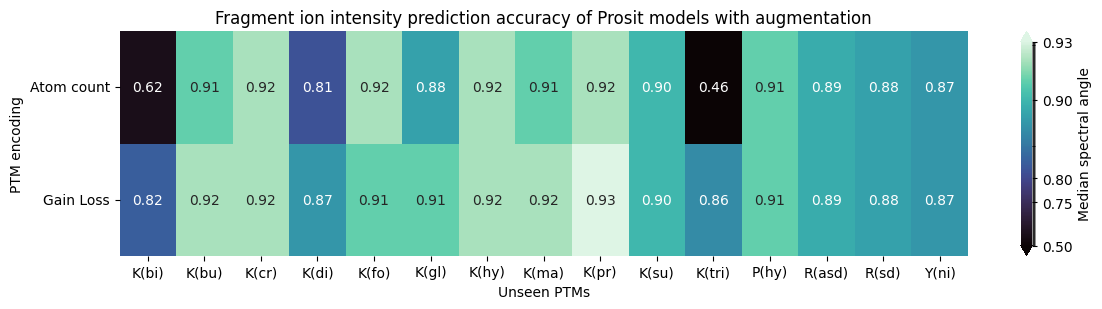

PTM,K(bi),K(bu),K(cr),K(di),K(fo),K(gl),K(hy),K(ma),K(pr),K(su),K(tri),P(hy),R(asd),R(sd),Y(ni)
PTM_encoding,,,,,,,,,,,,,,,
Atom count,0.62,0.91,0.92,0.81,0.92,0.88,0.92,0.91,0.92,0.9,0.46,0.91,0.89,0.88,0.87
Gain Loss,0.82,0.92,0.92,0.87,0.91,0.91,0.92,0.92,0.93,0.9,0.86,0.91,0.89,0.88,0.87


In [4]:
b = table('ED_Fig4b')
mat = b.pivot(index='PTM_encoding', columns='PTM', values='median_spectral_angle (spectral angle, 0-1)').loc[['Atom count', 'Gain Loss'], ptm_order]
bounds = np.concatenate([np.linspace(0.5, 0.7, 20), np.linspace(0.7, 0.8, 50)[1:], np.linspace(0.8, 0.9, 80)[1:], np.linspace(0.9, 0.93, 60)[1:]])
fig, ax = plt.subplots(figsize=(12, 3.2))
sns.heatmap(mat, cmap='mako', norm=BoundaryNorm(bounds, ncolors=256, extend='both'), annot=True, fmt='.2f',
            cbar_kws={'ticks': [0.5, 0.75, 0.8, 0.9, 0.93], 'format': '%.2f', 'label': 'Median spectral angle'}, ax=ax)
ax.set_xlabel('Unseen PTMs')
ax.set_ylabel('PTM encoding')
ax.set_title('Fragment ion intensity prediction accuracy of Prosit models with augmentation')
plt.yticks(rotation=0)
plt.tight_layout()
save('ED_Fig4b')
plt.show()
mat

## c, d — unseen amino-acid substitutions
One point per unseen amino-acid substitution; x = atom count, y = gain loss encoding (c: 95th percentile of the absolute
iRT error; d: median spectral angle). Substitutions are coloured in shades of one base colour per substituted amino acid (`from_aa`);
dashed line: identity.

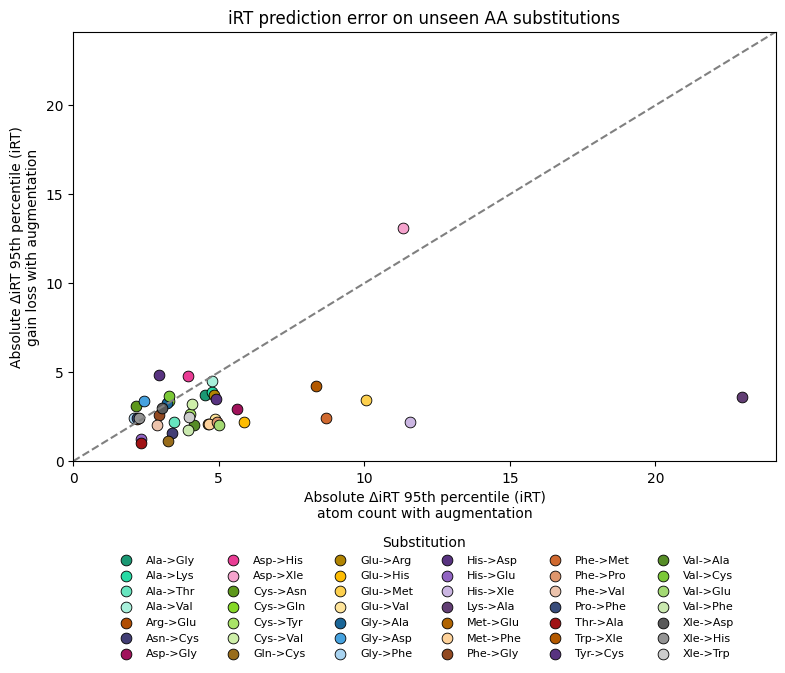

,substitution,x_atom_count_with_augmentation_absolute_delta_iRT_95th_percentile (iRT units),y_gain_loss_with_augmentation_absolute_delta_iRT_95th_percentile (iRT units)
0,His->Asp,4.91,3.51
1,Ala->Thr,3.47,2.19
2,Ala->Gly,4.52,3.72
3,Ala->Val,4.75,4.48
4,Cys->Tyr,4.01,2.68
5,Asp->His,3.94,4.80
6,Asp->Gly,5.62,2.96
7,Glu->Val,4.87,2.39
8,Phe->Val,2.87,2.01
9,Gly->Ala,3.23,3.30


In [5]:
BASE = {"Ala": "#1b9e77", "Arg": "#d95f02", "Asn": "#7570b3", "Asp": "#e7298a", "Cys": "#66a61e", "Glu": "#e6ab02",
        "Gln": "#a6761d", "Gly": "#1f78b4", "His": "#6a3d9a", "Lys": "#cab2d6", "Met": "#fdbf6f", "Phe": "#b15928",
        "Pro": "#8da0cb", "Thr": "#e31a1c", "Trp": "#ff7f00", "Tyr": "#6a3d9a", "Val": "#b2df8a"}


def palette(names):
    pal = {}
    s = pd.Series(sorted(set(names)))
    for aa, grp in s.groupby(s.str.split('->').str[0]):
        h, l, sat = colorsys.rgb_to_hls(*to_rgb(BASE.get(aa, '#7f7f7f')))
        n = len(grp)
        for i, name in enumerate(sorted(grp)):
            pal[name] = colorsys.hls_to_rgb(h, 0.35 + i * 0.45 / max(n - 1, 1), sat)
    return pal


def subs_scatter(df, x, y, xlabel, ylabel, title, name, lims=None):
    pal = palette(df['substitution'])
    order = sorted(df['substitution'], key=lambda s: (s.split('->')[0], s))
    fig, ax = plt.subplots(figsize=(8, 7))
    for s in order:
        r = df[df['substitution'] == s].iloc[0]
        ax.scatter(r[x], r[y], color=pal[s], s=60, edgecolor='black', linewidth=0.6, label=s)
    lo, hi = lims if lims else (min(df[x].min(), df[y].min()) * 0.98, max(df[x].max(), df[y].max()) * 1.02)
    ax.plot([lo, hi], [lo, hi], ls='--', color='gray')
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(title='Substitution', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=6, frameon=False, fontsize=8)
    plt.tight_layout()
    save(name)
    plt.show()


c = table('ED_Fig4c')
cx, cy = ('x_atom_count_with_augmentation_absolute_delta_iRT_95th_percentile (iRT units)',
          'y_gain_loss_with_augmentation_absolute_delta_iRT_95th_percentile (iRT units)')
subs_scatter(c, cx, cy, 'Absolute ΔiRT 95th percentile (iRT)\natom count with augmentation',
             'Absolute ΔiRT 95th percentile (iRT)\ngain loss with augmentation',
             'iRT prediction error on unseen AA substitutions', 'ED_Fig4c', lims=(0, max(c[cx].max(), c[cy].max()) * 1.05))
c[['substitution', cx, cy]].round(2)

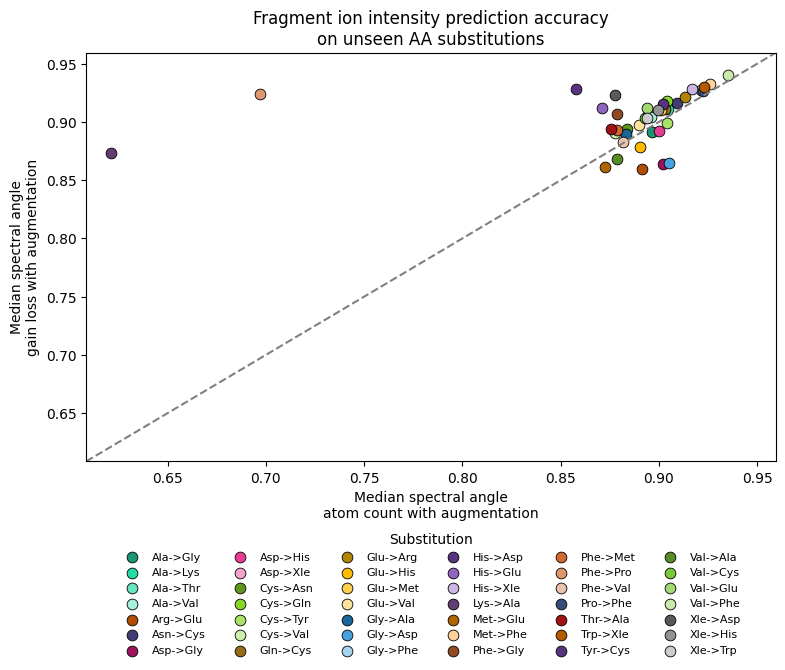

,substitution,"x_atom_count_with_augmentation_median_spectral_angle (spectral angle, 0-1)","y_gain_loss_with_augmentation_median_spectral_angle (spectral angle, 0-1)"
0,His->Asp,0.858,0.929
1,Ala->Thr,0.894,0.906
2,Ala->Gly,0.897,0.891
3,Ala->Val,0.896,0.904
4,Cys->Tyr,0.904,0.899
5,Asp->His,0.900,0.893
6,Asp->Gly,0.902,0.864
7,Glu->Val,0.890,0.898
8,Phe->Val,0.882,0.883
9,Gly->Ala,0.883,0.890


In [6]:
d = table('ED_Fig4d')
dx, dy = ('x_atom_count_with_augmentation_median_spectral_angle (spectral angle, 0-1)',
          'y_gain_loss_with_augmentation_median_spectral_angle (spectral angle, 0-1)')
subs_scatter(d, dx, dy, 'Median spectral angle\natom count with augmentation', 'Median spectral angle\ngain loss with augmentation',
             'Fragment ion intensity prediction accuracy\non unseen AA substitutions', 'ED_Fig4d')
d[['substitution', dx, dy]].round(3)

## e — with vs without sulfur-containing augmentations
One point per PTM; x = model trained without, y = model trained with sulfur-containing augmentations (median spectral
angle). PTMs differing by more than 0.03 are labelled.

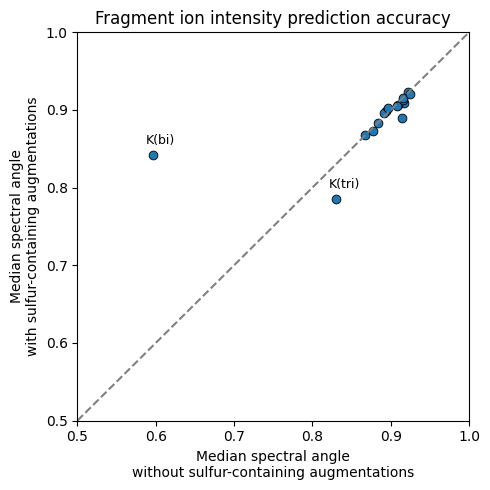

,PTM,"x_without_sulfur_containing_augmentations_median_spectral_angle (spectral angle, 0-1)","y_with_sulfur_containing_augmentations_median_spectral_angle (spectral angle, 0-1)"
0,K(ac),0.922,0.923
1,K(bi),0.596,0.842
2,K(bu),0.914,0.890
3,K(cr),0.917,0.909
4,K(di),0.867,0.868
5,K(fo),0.909,0.907
6,K(gl),0.894,0.898
7,K(hy),0.916,0.913
8,K(ma),0.915,0.916
9,K(me),0.891,0.896


In [7]:
e = table('ED_Fig4e')
ex, ey = ('x_without_sulfur_containing_augmentations_median_spectral_angle (spectral angle, 0-1)',
          'y_with_sulfur_containing_augmentations_median_spectral_angle (spectral angle, 0-1)')
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(e[ex], e[ey], color='#1f77b4', edgecolor='black', linewidth=0.6, s=40)
for _, r in e.iterrows():
    if abs(r[ey] - r[ex]) > 0.03:
        ax.annotate(r['PTM'], (r[ex], r[ey]), textcoords='offset points', xytext=(-5, 8), fontsize=9)
ax.plot([0.5, 1], [0.5, 1], ls='--', color='gray')
ax.set_xlim(0.5, 1)
ax.set_ylim(0.5, 1)
ax.set_xlabel('Median spectral angle\nwithout sulfur-containing augmentations')
ax.set_ylabel('Median spectral angle\nwith sulfur-containing augmentations')
ax.set_title('Fragment ion intensity prediction accuracy')
plt.tight_layout()
save('ED_Fig4e')
plt.show()
e[['PTM', ex, ey]].round(3)

## f — gain loss without augmentation vs augmentation-only model
One point per PTM (seen / unseen PTM); x = gain loss without augmentation, y = augmentation only (median spectral angle).

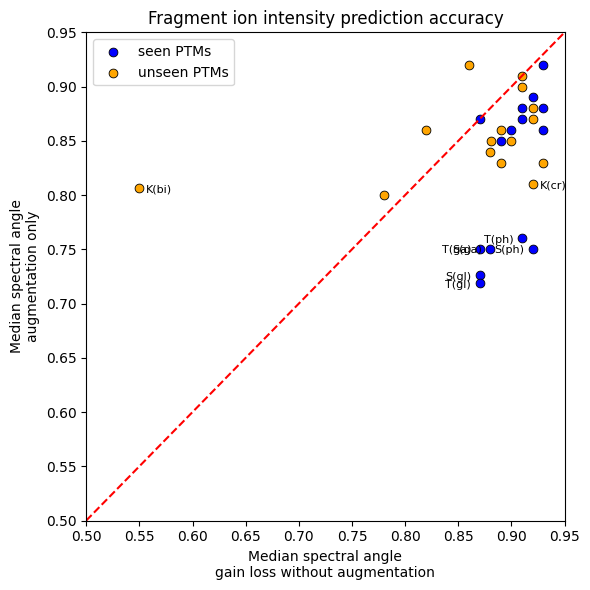

,PTM,group,"x_gain_loss_without_augmentation_median_spectral_angle (spectral angle, 0-1)","y_augmentation_only_median_spectral_angle (spectral angle, 0-1)"
0,K(ac),seen PTM,0.93,0.920
1,N-term(ac),seen PTM,0.87,0.870
2,R(cit),seen PTM,0.89,0.850
3,K(me),seen PTM,0.92,0.890
4,R(me),seen PTM,0.93,0.880
5,S(ph),seen PTM,0.92,0.750
6,T(ph),seen PTM,0.91,0.760
7,Y(ph),seen PTM,0.93,0.860
8,E(pyro),seen PTM,0.91,0.870
9,Q(pyro),seen PTM,0.90,0.860


In [8]:
f = table('ED_Fig4f')
fx, fy = ('x_gain_loss_without_augmentation_median_spectral_angle (spectral angle, 0-1)',
          'y_augmentation_only_median_spectral_angle (spectral angle, 0-1)')
colors = {'seen PTM': 'blue', 'unseen PTM': 'orange'}
fig, ax = plt.subplots(figsize=(6, 6))
for g, col in colors.items():
    s = f[f['group'] == g]
    ax.scatter(s[fx], s[fy], color=col, edgecolor='black', linewidth=0.6, s=40, label=g.replace('PTM', 'PTMs'))
for _, r in f.iterrows():
    if r[fx] - r[fy] > 0.1 or r[fx] < 0.7:
        ax.annotate(r['PTM'], (r[fx], r[fy]), textcoords='offset points', fontsize=8,
                    xytext=(-6, -3) if r['group'] == 'seen PTM' else (5, -3), ha='right' if r['group'] == 'seen PTM' else 'left')
lo = 0.5
ax.plot([lo, 0.95], [lo, 0.95], 'r--')
ax.set_xlim(lo, 0.95)
ax.set_ylim(lo, 0.95)
ax.set_xlabel('Median spectral angle\ngain loss without augmentation')
ax.set_ylabel('Median spectral angle\naugmentation only')
ax.set_title('Fragment ion intensity prediction accuracy')
ax.legend(loc='upper left')
plt.tight_layout()
save('ED_Fig4f')
plt.show()
f[['PTM', 'group', fx, fy]].round(3)